In [1]:
import pandas as pd
import numpy as np
import ast
import os
import shutil
base = os.path.dirname(os.path.abspath('.'))
base = base + '/orca_descriptors'

def load_table(path):
    path = str(path)
    if path.lower().endswith(('.csv',)):
        return pd.read_csv(path)
    elif path.lower().endswith(('.xls', '.xlsx')):
        return pd.read_excel(path)
    else:
        raise ValueError(f"Unsupported extension for {path}. Use .csv, .xls, or .xlsx")


def describe_col_type(series):
    s = series.rename('v')
    non_null = s.dropna()
    if non_null.empty:
        return 'x_nan'  # only nan/None values

    # numeric conversion check
    numeric = pd.to_numeric(non_null, errors='coerce')
    is_numeric = numeric.notna().all()

    if is_numeric:
        # check integerness of numeric values
        if np.all(np.floor(numeric) == numeric):
            return 'x_int'
        else:
            return 'x'

    # non-numeric at all -> string category/label
    return 'x_str'


def make_descriptor_encoding(desc_df, key='SMILES'):
    enc = {}
    x_i = 0
    x_str_j = 0
    x_nan_k = 0
    x_int_m = 0

    for col in desc_df.columns:
        if col == key:
            continue
        col_type = describe_col_type(desc_df[col])

        if col_type == 'x':
            enc[col] = f'x{x_i}'
            x_i += 1
        elif col_type == 'x_str':
            enc[col] = f'x_str{x_str_j}'
            x_str_j += 1
        elif col_type == 'x_nan':
            enc[col] = f'x_nan{x_nan_k}'
            x_nan_k += 1
        elif col_type == 'x_int':
            enc[col] = f'x_int{x_int_m}'
            x_int_m += 1
        else:
            enc[col] = f'x_unknown{col}'

    return enc


def merge_descriptor_target(desc_path, target_path, key='SMILES'):
    desc_df = load_table(desc_path)
    target_df = load_table(target_path)

    if key not in desc_df.columns:
        raise KeyError(f"Key '{key}' not found in descriptor file")
    if key not in target_df.columns:
        raise KeyError(f"Key '{key}' not found in target file")

    desc_smiles = set(desc_df[key].dropna().astype(str))
    target_smiles = set(target_df[key].dropna().astype(str))
    missing_from_desc = sorted(target_smiles - desc_smiles)
    if missing_from_desc:
        print(f"Warning: {len(missing_from_desc)} SMILES entries in target are missing from descriptor file and will be dropped in merged_df:")
        for s in missing_from_desc[:20]:
            print(f"  - {s}")
        if len(missing_from_desc) > 20:
            print(f"  ... and {len(missing_from_desc)-20} more")

    merged = pd.merge(desc_df, target_df, on=key, how='inner')
    encoding = make_descriptor_encoding(desc_df, key=key)

    return merged, encoding

In [2]:
### add the path to the descriptor and target files, and the desired output directory for ROBERT input
output_dir = 'ROBERT/test_splitseven'  # e.g. 'ROBERT/test_splitstratified'
split = 'even'     # options:    'even': splits the data evenly into training and test sets. (default)
                  #             'rnd': randomly splits the data.
                  #             'stratified': splits the data while preserving the distribution of the target variable. 
                  #             'KN': uses a k-means approach to select representative samples for training (good for intrapolation, bad for extrapolation). 
                  #             'extra_q1': selects the 20% lowest values.
                  #             'extra_q5': selects the 20% highest values.

### do you want to overwrite existing ROBERT input in the output directory??
overwrite = True
if not overwrite and os.path.exists(f'{output_dir}/CURATE'):
    print(f"Error: {output_dir}/CURATE already exists. \nSet overwrite=True to overwrite existing CURATE folder or choose a different output directory.")


In [3]:
merged_df, encoding = merge_descriptor_target('2026_03_20_library_pyox_2026_03_03_descriptor_stats.csv', 
                                              'experiment_data_ee.xlsx',
                                              key='INCHI')


### encode the column names to the format expected by ROBERT, and save the csv for ROBERT input
encoding_ = {k: v for k, v in encoding.items() if k != 'SMILES'}
decoding  = {v: k for k, v in encoding.items()}
renamed_df = merged_df.rename(columns=encoding_)
renamed_df.drop(columns=['INCHI', 'yield', 'ee', 'Unnamed: 3'], inplace=True)

## save the csv for ROBERT input
print(f"Saving ROBERT input to: {output_dir}/input.csv")
if not os.path.exists(output_dir):
    os.makedirs(output_dir)
renamed_df.to_csv(f'{output_dir}/input.csv', index=False)
renamed_df.head()

Saving ROBERT input to: ROBERT/test_splitseven/input.csv


,SMILES,x0,x1,x2,x3,x4,x5,x6,x7,x8,...,x144,x145,x146,x147,x148,x149,x150,x151,x152,ΔΔG
0,[H]C1=C(C(F)(F)F)C([H])=C([H])C(=C2N[C@@]([H])...,612.548589,673.698709,666.920440,29.144855,38.730646,33.219672,29.274148,38.480338,31.171054,...,-1.739980,5.143962,1.459692,-165.840076,177.655981,-13.656931,-177.735375,179.723912,-12.843016,0.918705
1,[H]C1=C(C(F)(F)F)C([H])=C([H])C(=C2N[C@@]([H])...,462.677690,467.267554,466.777259,27.443947,28.672819,27.595336,30.090111,31.799691,30.294490,...,-0.441620,2.169861,-0.065941,-179.956019,179.288505,-19.474517,-179.810518,179.368307,19.349415,0.487970
2,[H]C1=C([H])C([H])=C(OC([H])([H])[H])C(=C2N[C@...,454.260137,463.150446,462.987386,27.510367,31.805801,28.867824,27.523572,31.853497,30.496426,...,2.183491,3.377672,2.779180,-168.076319,-56.383203,-133.941816,98.432927,172.092391,149.059162,0.574355
3,[H]C1=C(SC([H])([H])[H])C([H])=C(F)C(=C2N[C@@]...,487.669562,488.189552,488.016955,28.240003,31.831029,31.507484,28.216352,31.693458,30.124095,...,1.905304,2.648976,2.276165,-167.605732,-49.269968,-67.999051,107.584007,171.119775,115.153110,0.047424
4,[H]C1=C(C(F)(F)F)C([H])=C(S(=O)(=O)C([H])([H])...,556.626009,562.656106,560.505908,28.680899,28.820835,28.760296,31.770324,31.892324,31.822519,...,6.686289,9.378712,7.631905,-169.279626,-167.497045,-168.165134,171.407367,174.017534,172.165095,0.083084


In [4]:
### This code used ROBERT to curate the data
### ref: https://robert.readthedocs.io/en/latest/index.html
from robert import curate as cur
curation = cur.curate(  csv_name=f'{output_dir}/input.csv',
                        y = 'ΔΔG',
                        names = 'SMILES',
                        )

### just some boring data cleaning and file moving to get the CURATE output into the desired output directory, and to avoid overwriting existing CURATE output if it already exists in the output directory
if overwrite and os.path.exists(f'{output_dir}/CURATE'):
    shutil.rmtree(f"{output_dir}/CURATE")
    print(f"Overwritten: {output_dir}/CURATE")
    shutil.move("CURATE", f"{output_dir}")  # destination option in curate() is currently broken, so we move the CURATE folder manually after curation is done
elif not os.path.exists(f'{output_dir}/CURATE'):
    print(f"CURATE output will be saved to: {output_dir}/CURATE")
    shutil.move("CURATE", f"{output_dir}")  # destination option in curate() is currently broken, so we move the CURATE folder manually after curation is done
else:
    print(f"Error: {output_dir}/CURATE already exists. \nSet overwrite=True to overwrite existing CURATE folder or choose a different output directory.")



/opt/homebrew/Caskroom/miniconda/base/envs/gp_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROBERT v 2.1.0 2026/03/24 10:36:06 
How to cite: Dalmau, D.; Alegre Requena, J. V. WIREs Comput Mol Sci. 2024, 14, e1733.



o  Starting data curation with the CURATE module


o  Database input.csv loaded successfully, including:
   - 25 datapoints
   - 153 accepted descriptors
   - 1 ignored descriptors
   - 0 discarded descriptors


o  Analyzing categorical variables
   - No categorical variables were found


o  Duplication filters activated
   Excluded datapoints:
   -  No datapoints were removed


o  Correlation filter activated with these thresholds: thres_x = 0.7
   Excluded descriptors:


   - x103 removed (R2 = 1.00 with x100), kept more predictive descriptor
   - x104 removed (R2 = 1.00 with x101), kept more predictive descriptor
   - x99 removed (R2 = 1.00 with x102), kept more predictive descriptor
   - x48 removed (R2 = 1.00 with x45), kept more predictive descriptor
   - x49 removed (R2 = 1.00 with x46), kept more predictive descriptor
   - x50 removed (R2 = 1.00 with x47)

ROBERT v 2.1.0 2026/03/24 10:36:06 
How to cite: Dalmau, D.; Alegre Requena, J. V. WIREs Comput Mol Sci. 2024, 14, e1733.



o  Starting generation of ML models with the GENERATE module


o  Database input_CURATE.csv loaded successfully, including:
   - 25 datapoints
   - 56 accepted descriptors
   - 1 ignored descriptors
   - 0 discarded descriptors


o  Starting heatmap scan with 4 ML models (['RF', 'GB', 'NN', 'MVL']).
   Heatmap generation:

   o Starting BO-based hyperoptimization using the combined target:
                    
     1. 50% = RMSE from a 10x repeated 3-fold CV (interpoplation)
                    
     2. 50% = RMSE from the bottom or top (worst performing) fold in a sorted 3-fold CV (extrapolation)
                    


   - 1/4 - ML model: RF 

      x Using general database (model-specific not found): input_CURATE.csv


o  Before hyperoptimization, 20% of the data (or 4 points at least) was separated as test set, using an even distribution of data points across

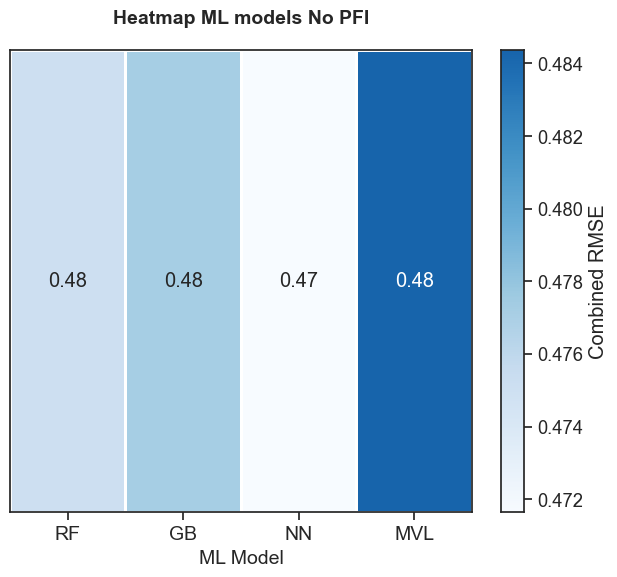

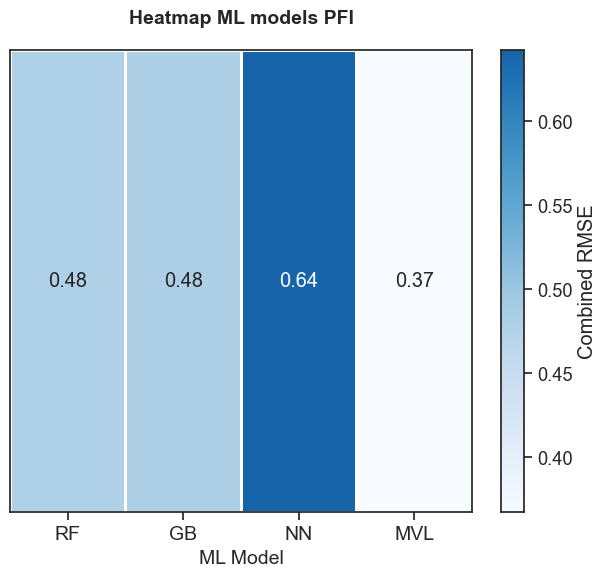

In [5]:
### this code used ROBERT to generate models (linear and non linear)
### ref: https://robert.readthedocs.io/en/latest/index.html
from robert import generate as gen 
### use the curated csv from ROBERT to generate models
gen.generate(csv_name=f'{output_dir}/CURATE/input_CURATE.csv', 
            y = 'ΔΔG',
            names = 'SMILES',
            split = split,
            pfi_epochs=5,
            kfold=3,
            seed=1)

### just some boring data cleaning and file moving to get the GENERATE output into the desired output directory, and to avoid overwriting existing GENERATE output if it already exists in the output directory
if overwrite and os.path.exists(f'{output_dir}/GENERATE'):
    shutil.rmtree(f"{output_dir}/GENERATE")
    print(f"Overwritten: {output_dir}/GENERATE")
    shutil.move("GENERATE", f"{output_dir}")  # destination option in generate() is currently broken, so we move the GENERATE folder manually after generation is done
elif not os.path.exists(f'{output_dir}/GENERATE'):
    print(f"GENERATE output will be saved to: {output_dir}/GENERATE")
    shutil.move("GENERATE", f"{output_dir}")  # destination option in generate() is currently broken, so we move the GENERATE folder manually after generation is done
else:
    print(f"Error: {output_dir}/GENERATE already exists. \nSet overwrite=True to overwrite existing GENERATE folder or choose a different output directory.")


In [6]:
### verify function using ROBERT
from robert import verify as verify
verify.verify(params_dir = f'{output_dir}/GENERATE/Best_model/')

### just some boring data cleaning and file moving to get the VERIFY output into the desired output directory, and to avoid overwriting existing VERIFY output if it already exists in the output directory
if overwrite and os.path.exists(f'{output_dir}/VERIFY'):
    shutil.rmtree(f"{output_dir}/VERIFY")
    print(f"Overwritten: {output_dir}/VERIFY")
    shutil.move("VERIFY", f"{output_dir}")  # destination option in verify() is currently broken, so we move the VERIFY folder manually after verification is done
elif not os.path.exists(f'{output_dir}/VERIFY'):
    print(f"VERIFY output will be saved to: {output_dir}/VERIFY")
    shutil.move("VERIFY", f"{output_dir}")  # destination option in verify() is currently broken, so we move the VERIFY folder manually after verification is done
else:
    print(f"Error: {output_dir}/VERIFY already exists. \nSet overwrite=True to overwrite existing VERIFY folder or choose a different output directory.")


ROBERT v 2.1.0 2026/03/24 10:36:06 
How to cite: Dalmau, D.; Alegre Requena, J. V. WIREs Comput Mol Sci. 2024, 14, e1733.



o  Starting tests to verify the prediction ability of the ML models with the VERIFY module



------- Starting model with all variables (No PFI) -------


o  Database NN_db.csv loaded successfully, including:
   - 25 datapoints
   - 56 accepted descriptors
   - 2 ignored descriptors
   - 0 discarded descriptors


o  ML model No_PFI (with no PFI filter) and Xy database were loaded, including:
   - Target value: ΔΔG
   - Names: SMILES
   - Model: NN
   - k-fold CV: 3
   - Repetitions CV: 10
   - Descriptors: ['x101', 'x102', 'x105', 'x112', 'x114', 'x117', 'x123', 'x126', 'x127', 'x128', 'x129', 'x130', 'x131', 'x132', 'x135', 'x136', 'x138', 'x139', 'x144', 'x145', 'x147', 'x148', 'x149', 'x150', 'x17', 'x24', 'x25', 'x26', 'x27', 'x29', 'x30', 'x33', 'x34', 'x37', 'x38', 'x40', 'x42', 'x43', 'x45', 'x46', 'x47', 'x5', 'x51', 'x52', 'x59', 'x6', 'x60', 'x61', 'x65

In [7]:
### predict function using ROBERT - check performance on test set
from robert import predict as predict
pred = predict.predict(params_dir = f'{output_dir}/GENERATE/Best_model/')

### just some boring data cleaning and file moving to get the PREDICT output into the desired output directory, and to avoid overwriting existing PREDICT output if it already exists in the output directory
if overwrite and os.path.exists(f'{output_dir}/PREDICT'):
    shutil.rmtree(f"{output_dir}/PREDICT")
    print(f"Overwritten: {output_dir}/PREDICT")
    shutil.move("PREDICT", f"{output_dir}")  # destination option in predict() is currently broken, so we move the PREDICT folder manually after prediction is done
elif not os.path.exists(f'{output_dir}/PREDICT'):
    print(f"PREDICT output will be saved to: {output_dir}/PREDICT")
    shutil.move("PREDICT", f"{output_dir}")  # destination option in predict() is currently broken, so we move the PREDICT folder manually after prediction is done
else:
    print(f"Error: {output_dir}/PREDICT already exists. \nSet overwrite=True to overwrite existing PREDICT folder or choose a different output directory.")


ROBERT v 2.1.0 2026/03/24 10:36:06 
How to cite: Dalmau, D.; Alegre Requena, J. V. WIREs Comput Mol Sci. 2024, 14, e1733.



o  Representation of predictions and analysis of ML models with the PREDICT module



------- Starting model with all variables (No PFI) -------


o  Database NN_db.csv loaded successfully, including:
   - 25 datapoints
   - 56 accepted descriptors
   - 2 ignored descriptors
   - 0 discarded descriptors


o  ML model No_PFI (with no PFI filter) and Xy database were loaded, including:
   - Target value: ΔΔG
   - Names: SMILES
   - Model: NN
   - k-fold CV: 3
   - Repetitions CV: 10
   - Descriptors: ['x101', 'x102', 'x105', 'x112', 'x114', 'x117', 'x123', 'x126', 'x127', 'x128', 'x129', 'x130', 'x131', 'x132', 'x135', 'x136', 'x138', 'x139', 'x144', 'x145', 'x147', 'x148', 'x149', 'x150', 'x17', 'x24', 'x25', 'x26', 'x27', 'x29', 'x30', 'x33', 'x34', 'x37', 'x38', 'x40', 'x42', 'x43', 'x45', 'x46', 'x47', 'x5', 'x51', 'x52', 'x59', 'x6', 'x60', 'x61', 'x65', 'x68'

In [8]:
### report function using ROBERT - generate report from predictions
from robert import report as report
os.chdir(output_dir)
rep = report.report()
os.chdir(base)


o  ROBERT_report.pdf was created successfully in the working directory!


In [9]:
# decode the ROBERT output back to original column names

best_model_path = [f for f in os.listdir(f'{output_dir}/GENERATE/Best_model/PFI/') if f.endswith('PFI.csv')][0]  # get the name of the PFI csv file in the Best_model/PFI folder
df_best_model = pd.read_csv(f'{output_dir}/GENERATE/Best_model/PFI/{best_model_path}')
parameters = ast.literal_eval(df_best_model.loc[0, "X_descriptors"])

decoded_parameters = [decoding[param] for param in parameters]
print("Decoded parameters used in the best model:")
for param, decoded in zip(parameters, decoded_parameters):
    print(f"{param} -> {decoded}")

Decoded parameters used in the best model:
x25 -> SASA_H1_max
x138 -> Sterimol_Ni_H2_L_min
x129 -> Sterimol_Ni_H1_L_min
x150 -> Dihed_C1_N1_Ni_H1_min
